# Cuaderno 15: Análisis de Componentes Principales (PCA)

**Idea central:** tenemos datos con muchas variables (dimensiones). Queremos encontrar *nuevos ejes* (combinaciones lineales de las variables originales) que:

1. sean **ortogonales** entre sí,
2. capturen la **mayor varianza** posible, en orden decreciente.

Si los primeros $k$ ejes capturan casi toda la varianza, podemos **reducir la dimensión** de $n$ a $k$ perdiendo poca información.

**Herramientas de álgebra lineal que usaremos:**
- Matriz de covarianza (simétrica) → Teorema espectral → diagonalización ortogonal $C = QDQ^T$.
- Cambio de base (los datos expresados en la base de autovectores).
- Descomposición en valores singulares (SVD), que da lo mismo de forma numéricamente más estable.

## 1. Datos de ejemplo en $\mathbb{R}^2$
Generamos una nube de puntos correlacionada.

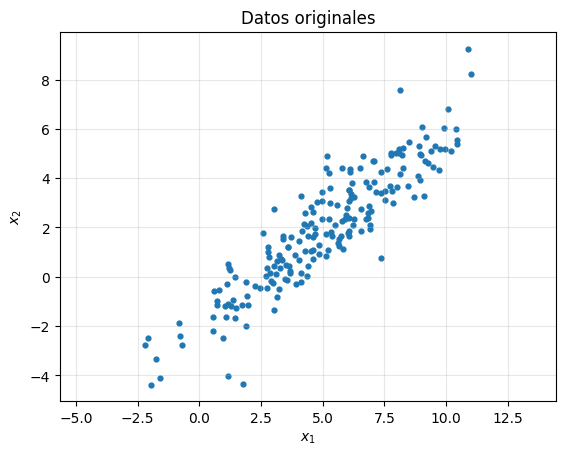

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

rng = np.random.default_rng(0)
n = 200
t = rng.normal(0, 3, n)
X = np.column_stack([t, 0.5*t + rng.normal(0, 1, n)])   # filas = observaciones, columnas = variables
X = X @ np.array([[1, 0.3], [0, 1]]) + np.array([5, 2])  # mezclamos un poco y desplazamos

plt.scatter(X[:,0], X[:,1], s=12)
plt.axis('equal'); plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title('Datos originales')
plt.grid(alpha=.3); plt.show()

## 2. Paso 1: centrar los datos
PCA trabaja con la varianza *alrededor de la media*, así que restamos a cada columna su media:

$$X_c = X - \mathbf{1}\bar{x}^T$$

In [2]:
media = X.mean(axis=0)
Xc = X - media
media, Xc.mean(axis=0)

(array([5.0458, 1.9481]), array([-0.,  0.]))

## 3. Paso 2: matriz de covarianza
Para datos centrados con $m$ observaciones:

$$C = \frac{1}{m-1} X_c^T X_c$$

- La diagonal $C_{ii}$ es la varianza de la variable $i$.
- $C_{ij}$ es la covarianza entre las variables $i$ y $j$.
- $C$ es **simétrica** y **semidefinida positiva** ⇒ por el teorema espectral tiene autovalores reales $\ge 0$ y autovectores ortogonales.

In [3]:
m = Xc.shape[0]
C = Xc.T @ Xc / (m - 1)
C, np.allclose(C, np.cov(X.T)), np.allclose(C, C.T)

(array([[8.3566, 6.4924],
        [6.4924, 6.0961]]),
 True,
 True)

## 4. Paso 3: autovalores y autovectores de $C$
Diagonalizamos: $C = Q D Q^T$ con $Q$ ortogonal.

- Las columnas de $Q$ (autovectores) son las **direcciones principales**.
- Cada autovalor $\lambda_i$ es la **varianza** de los datos a lo largo de esa dirección.

Usamos `eigh` (para matrices simétricas) y ordenamos de mayor a menor autovalor.

In [5]:
lam, Q = np.linalg.eigh(C)
orden = np.argsort(lam)[::-1]
lam, Q = lam[orden], Q[:, orden]

print("Autovalores (varianzas):", lam)
print("Autovectores (columnas):\n", Q)
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(2)))
print("C = Q D Q^T ?", np.allclose(C, Q @ np.diag(lam) @ Q.T))

Autovalores (varianzas): [13.8164  0.6363]
Autovectores (columnas):
 [[-0.7653  0.6436]
 [-0.6436 -0.7653]]
Q^T Q = I ? True
C = Q D Q^T ? True


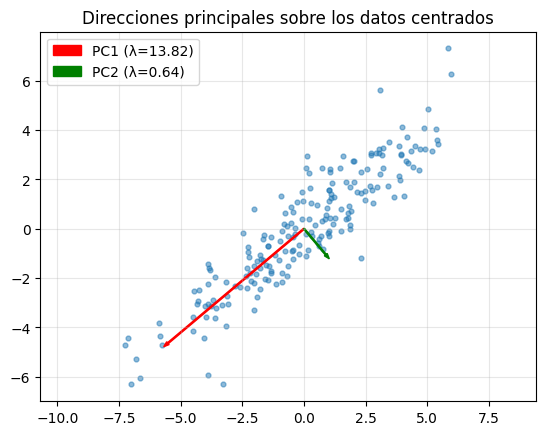

In [6]:
plt.scatter(Xc[:,0], Xc[:,1], s=12, alpha=.5)
for i, col in enumerate(['red', 'green']):
    v = Q[:, i] * 2*np.sqrt(lam[i])          # longitud = 2 desviaciones estándar
    plt.arrow(0, 0, v[0], v[1], color=col, width=0.05, length_includes_head=True,
              label=f'PC{i+1} (λ={lam[i]:.2f})')
plt.axis('equal'); plt.legend(); plt.grid(alpha=.3)
plt.title('Direcciones principales sobre los datos centrados'); plt.show()

## 5. Paso 4: proyectar (cambio de base)
Las coordenadas de los datos en la base de autovectores son

$$Z = X_c Q$$

La primera columna de $Z$ es el **primer componente principal** (PC1), la segunda es PC2, etc. En la nueva base la matriz de covarianza de $Z$ es **diagonal** $D$: las nuevas variables están *descorrelacionadas*.

In [ ]:
Z = Xc @ Q
print("Covarianza de Z:\n", np.cov(Z.T))
print("Varianzas:", Z.var(axis=0, ddof=1))

plt.scatter(Z[:,0], Z[:,1], s=12)
plt.axis('equal'); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.grid(alpha=.3)
plt.title('Datos en la base de componentes principales'); plt.show()

## 6. Varianza explicada y reducción de dimensión
La varianza total es $\operatorname{tr}(C) = \sum \lambda_i$. La fracción explicada por el componente $i$ es

$$\frac{\lambda_i}{\sum_j \lambda_j}$$

Para reducir a $k$ dimensiones nos quedamos con las primeras $k$ columnas de $Q$:

$$Z_k = X_c Q_k, \qquad \hat X = Z_k Q_k^T + \mathbf{1}\bar x^T \quad (\text{reconstrucción})$$

In [ ]:
print("Traza de C =", np.trace(C), " Suma de autovalores =", lam.sum())
print("Varianza explicada:", lam / lam.sum())

# Reducimos a 1 dimensión y reconstruimos
k = 1
Zk = Xc @ Q[:, :k]
Xrec = Zk @ Q[:, :k].T + media

plt.scatter(X[:,0], X[:,1], s=12, alpha=.4, label='original')
plt.scatter(Xrec[:,0], Xrec[:,1], s=12, color='red', label='reconstrucción con 1 PC')
plt.axis('equal'); plt.legend(); plt.grid(alpha=.3); plt.show()

error = np.mean(np.sum((X - Xrec)**2, axis=1))
print("Error cuadrático medio:", error, "≈ λ2 * (m-1)/m =", lam[1]*(m-1)/m)

**Observación:** el error de reconstrucción es justamente la varianza de las direcciones que descartamos. PCA da la mejor aproximación lineal de rango $k$ en el sentido de mínimos cuadrados (conexión con el cuaderno de mínimos cuadrados).

## 7. PCA mediante SVD
Si $X_c = U\Sigma V^T$ (SVD), entonces

$$C = \frac{1}{m-1}X_c^TX_c = V\,\frac{\Sigma^2}{m-1}\,V^T$$

Es decir:
- las columnas de $V$ son los autovectores de $C$ (direcciones principales),
- $\lambda_i = \sigma_i^2/(m-1)$,
- $Z = X_cV = U\Sigma$.

Es la forma que usan las librerías (no hace falta formar $C$).

In [ ]:
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("λ vía SVD:", S**2 / (m-1))
print("λ vía eigh:", lam)
print("Mismas direcciones (salvo signo)?", np.allclose(np.abs(Vt.T), np.abs(Q)))
print("Z = U Σ ?", np.allclose(np.abs(Xc @ Vt.T), np.abs(U * S)))

## 8. Ejemplo en 4 dimensiones (4 variables → 2)
Simulamos 3 especies de flores con 4 medidas cada una (largo/ancho de sépalo y pétalo), parecido al clásico dataset Iris. Proyectamos a 2 dimensiones para poder graficar.

In [ ]:
rng = np.random.default_rng(1)
nombres_var = ['largo sépalo', 'ancho sépalo', 'largo pétalo', 'ancho pétalo']
especies = ['A', 'B', 'C']
centros = np.array([[5.0, 3.4, 1.5, 0.2], [5.9, 2.8, 4.3, 1.3], [6.6, 3.0, 5.5, 2.0]])
L = np.array([[0.5, 0, 0, 0], [0.2, 0.3, 0, 0], [0.3, 0.1, 0.4, 0], [0.1, 0.05, 0.1, 0.15]])  # correlaciones
Xi = np.vstack([c + rng.normal(size=(50, 4)) @ L.T for c in centros])
yi = np.repeat([0, 1, 2], 50)
print(nombres_var, Xi.shape)

# PCA a mano
mi = Xi.mean(axis=0)
Xic = Xi - mi
Ci = np.cov(Xic.T)
li, Qi = np.linalg.eigh(Ci)
o = np.argsort(li)[::-1]; li, Qi = li[o], Qi[:, o]

print("Varianza explicada:", li / li.sum())
print("Acumulada:", np.cumsum(li) / li.sum())
print("Cargas (columnas = PCs):\n", Qi)

In [ ]:
Zi = Xic @ Qi[:, :2]
for c, nombre in enumerate(especies):
    plt.scatter(Zi[yi==c, 0], Zi[yi==c, 1], label=nombre, s=18)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(); plt.grid(alpha=.3)
plt.title('Datos proyectados a 2 componentes principales'); plt.show()

In [ ]:
# Gráfico de codo (scree plot)
plt.bar(range(1, 5), li / li.sum())
plt.plot(range(1, 5), np.cumsum(li) / li.sum(), 'o-', color='red', label='acumulada')
plt.xticks(range(1, 5)); plt.xlabel('Componente'); plt.ylabel('Varianza explicada')
plt.legend(); plt.title('Scree plot'); plt.show()

### Comparación con scikit-learn

In [ ]:
try:
    from sklearn.decomposition import PCA   # requiere: pip install scikit-learn
    pca = PCA(n_components=2).fit(Xi)
    print("sklearn varianza explicada:", pca.explained_variance_ratio_)
    print("A mano                   :", (li / li.sum())[:2])
    print("Mismos ejes (salvo signo):", np.allclose(np.abs(pca.components_), np.abs(Qi[:, :2].T)))
except ImportError:
    print("scikit-learn no está instalado; el cálculo a mano ya es el PCA completo.")

## 9. Importancia de la escala: estandarizar
PCA es sensible a las unidades: una variable con valores grandes domina la varianza. Si las variables tienen escalas distintas, se **estandariza** (restar media y dividir por desviación estándar), lo que equivale a hacer PCA sobre la **matriz de correlación**.

In [ ]:
Xe = Xi.copy()
Xe[:, 0] *= 100          # cambiamos las unidades de la primera variable

def var_expl(M):
    l = np.sort(np.linalg.eigvalsh(np.cov(M.T)))[::-1]
    return l / l.sum()

print("Original            :", var_expl(Xi))
print("Escala distorsionada:", var_expl(Xe))
Xs = (Xe - Xe.mean(0)) / Xe.std(0, ddof=1)
print("Estandarizado       :", var_expl(Xs))

## Resumen del algoritmo

1. Centrar (y, si hace falta, estandarizar) los datos: $X_c$.
2. Calcular $C = \frac{1}{m-1}X_c^TX_c$ (o la SVD de $X_c$).
3. Diagonalizar ortogonalmente: $C = QDQ^T$, ordenando $\lambda_1\ge\lambda_2\ge\dots$
4. Elegir $k$ según la varianza explicada acumulada.
5. Proyectar: $Z_k = X_cQ_k$. Reconstruir: $\hat X = Z_kQ_k^T + \mathbf 1\bar x^T$.

## Ejercicios
1. Demuestre que $C$ es semidefinida positiva (pista: $v^TCv = \frac{1}{m-1}\|X_cv\|^2$).
2. Demuestre que la varianza de los datos proyectados sobre un vector unitario $v$ es $v^TCv$, y que se maximiza con el autovector de mayor autovalor.
3. Para los datos del ejemplo 4D, ¿cuántos componentes se necesitan para explicar al menos el 99% de la varianza?
4. Aplique PCA con $k=1,2,3$ a los datos 4D y compare el error de reconstrucción con $\sum_{i>k}\lambda_i$.
5. Verifique con datos propios que PC1 y PC2 están descorrelacionados.